In [1]:
import os
import pandas as pd
from tqdm import tqdm

**1. Tentukan 2 periode waktu sebagai filter dari data interaksi.**

In [3]:
# Lokasi dataset asli
CSV_FILE_PATH = os.path.join("data", "events.csv")

# Folder untuk menyimpan hasil filter
OUTPUT_DIR = "data/filtered"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Periode training
TRAIN_START = pd.Timestamp("2015-07-05", tz="UTC")
TRAIN_END = pd.Timestamp("2015-07-27", tz="UTC")  # batas eksklusif

# Periode testing
TEST_START = pd.Timestamp("2015-07-27", tz="UTC")
TEST_END = pd.Timestamp("2015-08-17", tz="UTC")  # batas eksklusif

print("Periode training:", TRAIN_START.date(), "s.d.", (TRAIN_END - pd.Timedelta(days=1)).date())
print("Periode testing :", TEST_START.date(), "s.d.", (TEST_END - pd.Timedelta(days=1)).date())

Periode training: 2015-07-05 s.d. 2015-07-26
Periode testing : 2015-07-27 s.d. 2015-08-16


C:\Users\Huda\AppData\Local\Temp\ipykernel_23740\2070084520.py:16: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  print("Periode training:", TRAIN_START.date(), "s.d.", (TRAIN_END - pd.Timedelta(days=1)).date())
C:\Users\Huda\AppData\Local\Temp\ipykernel_23740\2070084520.py:17: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  print("Periode testing :", TEST_START.date(), "s.d.", (TEST_END - pd.Timedelta(days=1)).date())


**2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!**

In [5]:
# Hapus hasil sebelumnya
train_path = os.path.join(OUTPUT_DIR, "training.csv")
test_path = os.path.join(OUTPUT_DIR, "testing.csv")
filtered_path = os.path.join(OUTPUT_DIR, "filtered_events.csv")

for path in [train_path, test_path, filtered_path]:
    if os.path.exists(path):
        os.remove(path)

train_count = test_count = 0
batch_size = 100_000

for chunk in tqdm(
    pd.read_csv(CSV_FILE_PATH, chunksize=batch_size),
    desc="Filter tanggal"
):
    dates = pd.to_datetime(chunk["timestamp"], unit="ms", utc=True)

    train = chunk[(dates >= TRAIN_START) & (dates < TRAIN_END)].copy()
    test = chunk[(dates >= TEST_START) & (dates < TEST_END)].copy()

    for data, path, period in [
        (train, train_path, "training"),
        (test, test_path, "testing")
    ]:
        if not data.empty:
            data.to_csv(path, mode="a", index=False, header=not os.path.exists(path))

            data["period"] = period
            data.to_csv(
                filtered_path, mode="a", index=False,
                header=not os.path.exists(filtered_path)
            )

    train_count += len(train)
    test_count += len(test)

print("\nFilter selesai!")
print(f"Jumlah baris training: {train_count:,}")
print(f"Jumlah baris testing : {test_count:,}")
print(f"Total data terfilter : {train_count + test_count:,}")
print("File tersimpan di:", OUTPUT_DIR)

Filter tanggal: 0it [00:00, ?it/s]

Filter tanggal: 28it [00:09,  2.84it/s]


Filter selesai!
Jumlah baris training: 505,275
Jumlah baris testing : 393,659
Total data terfilter : 898,934
File tersimpan di: data/filtered


In [6]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

for name, df in [("Training", train_df), ("Testing", test_df)]:
    dates = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

    print(f"\n{name}")
    print("Jumlah baris:", len(df))
    print("Tanggal paling awal:", dates.min())
    print("Tanggal paling akhir:", dates.max())
    print("Jenis event:")
    print(df["event"].value_counts())


Training
Jumlah baris: 505275
Tanggal paling awal: 2015-07-05 00:00:14.030000+00:00
Tanggal paling akhir: 2015-07-26 23:59:58.790000+00:00
Jenis event:
event
view           488837
addtocart       12420
transaction      4018
Name: count, dtype: int64

Testing
Jumlah baris: 393659
Tanggal paling awal: 2015-07-27 00:00:00.548000+00:00
Tanggal paling akhir: 2015-08-16 23:59:55.927000+00:00
Jenis event:
event
view           379767
addtocart       10563
transaction      3329
Name: count, dtype: int64


 **3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

menghubungkan ke neo4j

In [7]:
from neo4j import GraphDatabase
import pandas as pd

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "Endangsri123!"
DATABASE = "retail-rocket"

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

with driver.session(database=DATABASE) as session:
    result = session.run("RETURN 1 AS hasil")
    print("Tes koneksi:", result.single()["hasil"])

Tes koneksi: 1


menentukan batas waktu untuk query cypher

In [ ]:
TRAIN_START_MS = int(pd.Timestamp("2015-07-05", tz="UTC").timestamp() * 1000)
TRAIN_END_MS = int(pd.Timestamp("2015-07-27", tz="UTC").timestamp() * 1000)

print("Batas awal:", TRAIN_START_MS)
print("Batas akhir eksklusif:", TRAIN_END_MS)

Batas awal: 1436054400000
Batas akhir eksklusif: 1437955200000


menghitung jumlah node dan relasi

In [10]:
query_composition = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start
  AND r.timestamp < $end
RETURN
    count(DISTINCT v) AS total_visitor,
    count(DISTINCT i) AS total_item,
    count(r) AS total_relasi
"""

with driver.session(database=DATABASE) as session:
    result = session.run(
        query_composition,
        start=TRAIN_START_MS,
        end=TRAIN_END_MS
    )

    record = result.single()

    print("Komposisi subgraph training")
    print("Total Visitor:", record["total_visitor"])
    print("Total Item:", record["total_item"])
    print("Total Relasi:", record["total_relasi"])

Komposisi subgraph training
Total Visitor: 278635
Total Item: 107628
Total Relasi: 505275


hitung masing-masing jenis relasi

In [11]:
query_relation_types = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start
  AND r.timestamp < $end
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database=DATABASE) as session:
    result = session.run(
        query_relation_types,
        start=TRAIN_START_MS,
        end=TRAIN_END_MS
    )

    relation_data = [
        dict(record)
        for record in result
    ]

relation_df = pd.DataFrame(relation_data)
display(relation_df)

,jenis_relasi,jumlah
0,VIEWED,488837
1,ADDED_TO_CART,12420
2,BOUGHT,4018


visualisasi komposisi subgraph

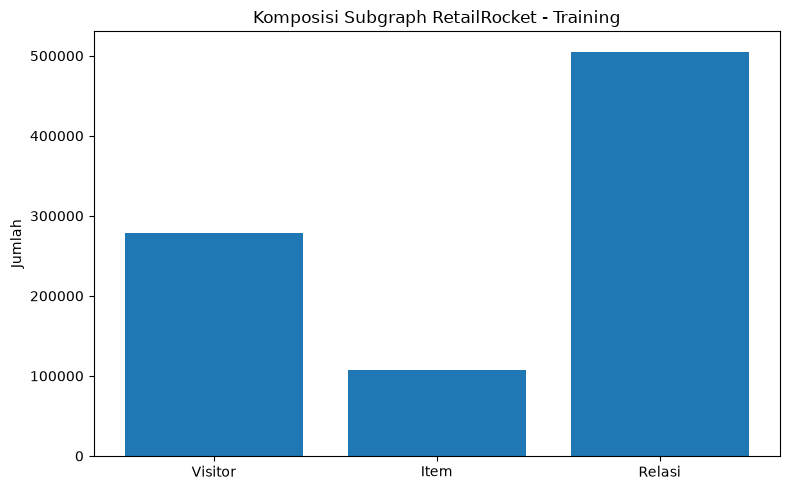

In [ ]:
import matplotlib.pyplot as plt

with driver.session(database=DATABASE) as session:
    result = session.run(
        query_composition,
        start=TRAIN_START_MS,
        end=TRAIN_END_MS
    )
    record = result.single()

node_labels = ["Visitor", "Item", "Relasi"]
node_counts = [record["total_visitor"], record["total_item"], record["total_relasi"]]

plt.figure(figsize=(8, 5))
plt.bar(node_labels, node_counts)
plt.title("Komposisi Subgraph RetailRocket - Training")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

Komposisi subgraph diperoleh melalui Python API Neo4j Driver dengan menjalankan query Cypher yang membatasi relasi berdasarkan nilai timestamp pada periode training. Jenis simpul yang diamati adalah Visitor dan Item, sedangkan hubungan antarsimpul merepresentasikan aktivitas pengunjung terhadap produk. Jumlah setiap jenis relasi dihitung menggunakan fungsi agregasi count(), sedangkan jumlah simpul dihitung menggunakan count(DISTINCT ...) agar setiap simpul hanya dihitung satu kali.

**4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

import library

In [14]:
import networkx as nx

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

baca dataset

In [15]:
TRAIN_PATH = "data/filtered/training.csv"

train_df = pd.read_csv(TRAIN_PATH)

print("Ukuran data training:", train_df.shape)
display(train_df.head())

Ukuran data training: (505275, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1436064906137,1087751,view,461686,NaN
1,1436064395637,1174931,view,294476,NaN
2,1436064149670,1249894,view,274935,NaN
3,1436066411783,390521,view,30391,NaN
4,1436062571713,455655,view,186431,NaN


membuat matriks VSM user-item

In [16]:
# Mengambil pasangan user-item unik
interactions = train_df[["visitorid", "itemid"]].drop_duplicates()

# Membuat indeks numerik untuk setiap user dan item
user_ids = interactions["visitorid"].unique()
item_ids = interactions["itemid"].unique()

user_to_idx = {user: idx for idx, user in enumerate(user_ids)}
item_to_idx = {item: idx for idx, item in enumerate(item_ids)}

rows = interactions["visitorid"].map(user_to_idx).to_numpy()
cols = interactions["itemid"].map(item_to_idx).to_numpy()

# Matriks sparse agar lebih hemat memori
user_item_matrix = csr_matrix(
    (
        np.ones(len(interactions), dtype=np.float32),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Shape VSM User-Item:", user_item_matrix.shape)
print("Jumlah interaksi unik:", user_item_matrix.nnz)

Jumlah user: 278635
Jumlah item: 107628
Shape VSM User-Item: (278635, 107628)
Jumlah interaksi unik: 403241


karakteristik dimensi dan kepadatan matriks

In [17]:
n_users, n_items = user_item_matrix.shape
total_possible = n_users * n_items
density = user_item_matrix.nnz / total_possible if total_possible else 0

print("Dimensi matriks:", user_item_matrix.ndim)
print("Shape:", user_item_matrix.shape)
print("Jumlah nilai nonzero:", user_item_matrix.nnz)
print(f"Densitas matriks: {density:.8%}")
print(f"Sparsity matriks: {1 - density:.8%}")

Dimensi matriks: 2
Shape: (278635, 107628)
Jumlah nilai nonzero: 403241
Densitas matriks: 0.00134463%
Sparsity matriks: 99.99865537%


membuat proyeksi user-user

In [ ]:
import numpy as np

# Menghitung banyaknya item unik yang diakses setiap user
user_activity = np.asarray(
    user_item_matrix.sum(axis=1)
).ravel()

top_user_idx = np.argsort(user_activity)[-30:][::-1]
top_user_ids = user_ids[top_user_idx]

# Matriks interaksi khusus 30 user teraktif
user_sample_matrix = user_item_matrix[top_user_idx]

# Menghitung cosine similarity antarpengguna
user_similarity = cosine_similarity(user_sample_matrix)

print("Shape matriks user sample:", user_sample_matrix.shape)
print("Shape similarity User-User:", user_similarity.shape)

Shape matriks user sample: (30, 107628)
Shape similarity User-User: (30, 30)


visualisasi graph user-user

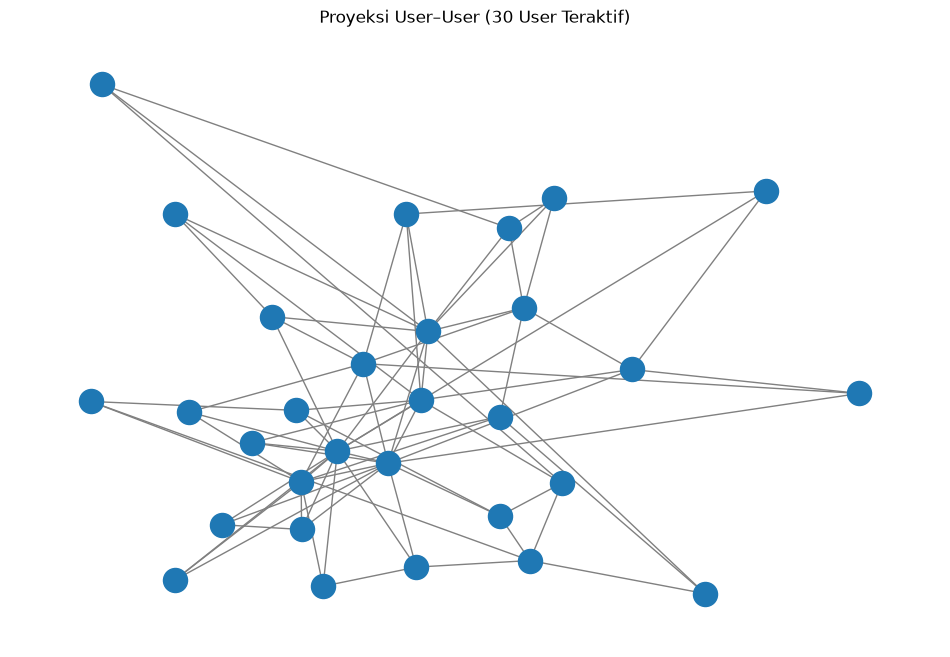

Jumlah simpul graph User: 30
Jumlah sisi graph User: 76


In [ ]:
G_user = nx.Graph()

for i, user in enumerate(top_user_ids):
    G_user.add_node(int(user))

for i in range(len(top_user_ids)):
    scores = user_similarity[i].copy()
    scores[i] = 0  # Mengabaikan similarity dengan dirinya sendiri

    # Maksimal tiga tetangga terdekat
    neighbors = np.argsort(scores)[::-1][:3]

    for j in neighbors:
        if scores[j] > 0:
            G_user.add_edge(
                int(top_user_ids[i]),
                int(top_user_ids[j]),
                weight=float(scores[j])
            )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(G_user, pos, with_labels=False, node_size=300, edge_color="gray")

plt.title("Proyeksi User–User (30 User Teraktif)")
plt.axis("off")
plt.show()

print("Jumlah simpul graph User:", G_user.number_of_nodes())
print("Jumlah sisi graph User:", G_user.number_of_edges())

Vector Space Modelling pada simpul User dilakukan dengan merepresentasikan setiap pengunjung sebagai vektor interaksi terhadap seluruh item. Matriks interaksi dibangun dalam bentuk sparse dengan nilai biner, yaitu 1 apabila pengunjung pernah berinteraksi dengan suatu item dan 0 apabila tidak. Kemiripan antaruser dihitung menggunakan cosine similarity. Visualisasi NetworkX menggunakan 30 user dengan aktivitas tertinggi agar pola hubungan lebih mudah diamati. Pemilihan sampel visualisasi tidak mengubah dimensi matriks VSM keseluruhan.

**5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

membuat proyeksi item-item

In [21]:
# Menghitung banyaknya user unik yang berinteraksi dengan setiap item
item_activity = np.asarray(
    user_item_matrix.sum(axis=0)
).ravel()

# Memilih 30 item dengan interaksi terbanyak
top_item_idx = np.argsort(item_activity)[-30:][::-1]
top_item_ids = item_ids[top_item_idx]

# Setiap baris sekarang merepresentasikan satu item
item_sample_matrix = user_item_matrix[:, top_item_idx].T.tocsr()

item_similarity = cosine_similarity(item_sample_matrix)

print("Jumlah item dalam sampel:", len(top_item_ids))
print("Shape matriks Item-User:", item_sample_matrix.shape)
print("Shape similarity Item-Item:", item_similarity.shape)

Jumlah item dalam sampel: 30
Shape matriks Item-User: (30, 278635)
Shape similarity Item-Item: (30, 30)


visualisasi graph item-item

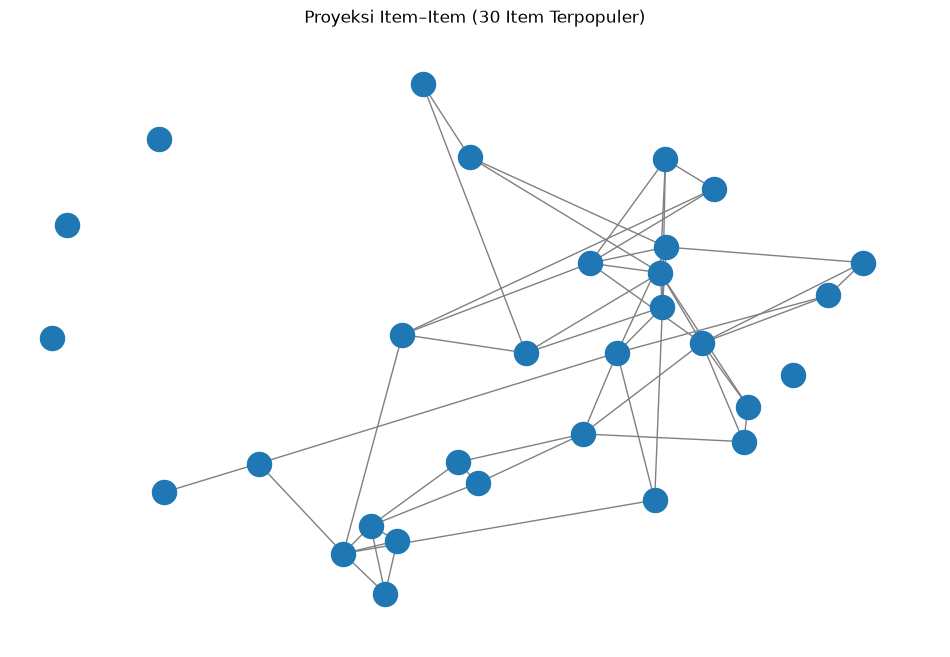

Jumlah simpul graph Item: 30
Jumlah sisi graph Item: 53


In [22]:
G_item = nx.Graph()

for item in top_item_ids:
    G_item.add_node(int(item))

for i in range(len(top_item_ids)):
    scores = item_similarity[i].copy()
    scores[i] = 0

    neighbors = np.argsort(scores)[::-1][:3]

    for j in neighbors:
        if scores[j] > 0:
            G_item.add_edge(
                int(top_item_ids[i]),
                int(top_item_ids[j]),
                weight=float(scores[j])
            )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=False,
    node_size=300,
    edge_color="gray"
)

plt.title("Proyeksi Item–Item (30 Item Terpopuler)")
plt.axis("off")
plt.show()

print("Jumlah simpul graph Item:", G_item.number_of_nodes())
print("Jumlah sisi graph Item:", G_item.number_of_edges())

membandingkan karakteristik kedua proyeksi

In [23]:
comparison_df = pd.DataFrame({
    "Karakteristik": [
        "Jumlah simpul VSM penuh",
        "Jumlah fitur per simpul",
        "Jumlah simpul visualisasi",
        "Jumlah sisi graph visualisasi"
    ],
    "Proyeksi User": [
        user_item_matrix.shape[0],
        user_item_matrix.shape[1],
        G_user.number_of_nodes(),
        G_user.number_of_edges()
    ],
    "Proyeksi Item": [
        user_item_matrix.shape[1],
        user_item_matrix.shape[0],
        G_item.number_of_nodes(),
        G_item.number_of_edges()
    ]
})

display(comparison_df)

,Karakteristik,Proyeksi User,Proyeksi Item
0,Jumlah simpul VSM penuh,278635,107628
1,Jumlah fitur per simpul,107628,278635
2,Jumlah simpul visualisasi,30,30
3,Jumlah sisi graph visualisasi,76,53


Vector Space Modelling pada simpul Item dilakukan dengan merepresentasikan setiap item berdasarkan pola interaksi pengunjung. Setiap item memiliki vektor yang dimensinya sama dengan jumlah user pada data training. Cosine similarity digunakan untuk mengukur kemiripan pola pengunjung antarpasangan item. Graph NetworkX dibangun dari 30 item dengan jumlah interaksi tertinggi untuk memperlihatkan hubungan kemiripan di antara item-item tersebut.

**6. Berdasarkan eksplorasi no 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!**

Berdasarkan hasil eksplorasi, proyeksi Item–Item lebih unggul dari segi potensi efisiensi komputasi, karena jumlah simpulnya lebih sedikit dan ukuran matriks similarity penuhnya lebih kecil. Sementara itu, proyeksi User–User lebih sesuai apabila tujuan analisis adalah menemukan pengguna dengan pola interaksi serupa, sehingga dapat digunakan untuk sistem rekomendasi berbasis KNN pengguna.

Jumlah sisi pada visualisasi User–User yang lebih besar, yaitu 76 sisi dibandingkan 53 sisi pada Item–Item, tidak secara langsung membuktikan bahwa proyeksi User–User lebih efektif. Jumlah tersebut dipengaruhi oleh kemiripan antaranggota sampel serta pemilihan tiga tetangga terdekat untuk setiap simpul. Oleh karena itu, pemilihan proyeksi sebaiknya disesuaikan dengan tujuan rekomendasi dan dievaluasi menggunakan metrik kinerja, seperti Hit@5 dan NDCG@5, pada tugas selanjutnya.

**7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python**
**a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!**
**b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!**

hitung similarity untuk satu user

In [32]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# Tentukan user referensi
reference_user = 974226

# Cari indeks user referensi di user_ids
ref_idx = np.where(user_ids == reference_user)[0][0]

# Hitung kemiripan user referensi terhadap semua user
similarity_scores = cosine_similarity(
    user_item_matrix[ref_idx],
    user_item_matrix
).ravel()

# User tidak dibandingkan dengan dirinya sendiri
similarity_scores[ref_idx] = -1

# Ambil 5 user dengan similarity tertinggi
top5_idx = np.argsort(similarity_scores)[-5:][::-1]

# Buat DataFrame hasil
top5_users = pd.DataFrame({
    "reference_user": reference_user,
    "similar_user": [int(user_ids[i]) for i in top5_idx],
    "similarity": [float(similarity_scores[i]) for i in top5_idx]
})

print("User referensi:", reference_user)
display(top5_users)

User referensi: 974226


,reference_user,similar_user,similarity
0,974226,1369103,0.147264
1,974226,1376763,0.138190
2,974226,205924,0.121487
3,974226,239362,0.109764
4,974226,1295687,0.109764


simpan relasi ke neo4j

In [33]:
# Ubah hasil DataFrame menjadi list dictionary untuk Neo4j
similarity_records = top5_users.to_dict(orient="records")

cypher_save = """
UNWIND $records AS row
MATCH (u:Visitor {visitorId: row.reference_user})
MATCH (v:Visitor {visitorId: row.similar_user})
MERGE (u)-[r:SIMILAR_TO]->(v)
SET r.similarity = row.similarity,
    r.method = 'cosine_similarity',
    r.period = 'training_2015-07-05_to_2015-07-26'
RETURN count(r) AS jumlah_relasi
"""

with driver.session(database=DATABASE) as session:
    result = session.run(
        cypher_save,
        records=similarity_records
    )
    print("Relasi similarity tersimpan:", result.single()["jumlah_relasi"])

Relasi similarity tersimpan: 5


query lima similarity tertinggi menggunakan cypher

In [34]:
cypher_top5 = """
MATCH (u:Visitor {visitorId: $reference_user})-[r:SIMILAR_TO]->(v:Visitor)
RETURN u.visitorId AS user_referensi,
       v.visitorId AS user_mirip,
       r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    result = session.run(
        cypher_top5,
        reference_user=reference_user
    )
    hasil_similarity = pd.DataFrame([record.data() for record in result])

display(hasil_similarity)

,user_referensi,user_mirip,similarity
0,974226,1369103,0.147264
1,974226,1376763,0.138190
2,974226,205924,0.121487
3,974226,239362,0.109764
4,974226,1295687,0.109764


**8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!**

sebelum

![Hasil User Similarity](image/sebelum-perhitungan.png)

sesudah

![Hasil User Similarity](image/setelah-perhitungan.png)

**9. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!**

membaca data training dan desting

In [134]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

train_df = pd.read_csv("data/filtered/training.csv")
test_df = pd.read_csv("data/filtered/testing.csv")

print("Jumlah data training:", len(train_df))
print("Jumlah data testing:", len(test_df))

Jumlah data training: 505275
Jumlah data testing: 393659


membuat matriks user-item

In [146]:
interactions = train_df[["visitorid", "itemid"]].drop_duplicates()

user_ids = interactions["visitorid"].unique()
item_ids = interactions["itemid"].unique()

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = interactions["visitorid"].map(user_to_idx).to_numpy()
cols = interactions["itemid"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (np.ones(len(interactions)), (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

print("Shape matriks:", user_item_matrix.shape)
print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))

Shape matriks: (278635, 107628)
Jumlah user: 278635
Jumlah item: 107628


memilih user secara reproducible

In [147]:
eligible_users = sorted(
    set(train_df["visitorid"]) & set(test_df["visitorid"])
)

rng = np.random.default_rng(2026)
target_user = None

for u in rng.permutation(eligible_users):
    u = int(u)

    if u not in user_to_idx:
        continue

    idx = user_to_idx[u]

    if user_item_matrix[idx].nnz >= 5:
        target_user = u
        target_idx = idx
        break

if target_user is None:
    raise ValueError("Tidak ditemukan user yang memenuhi kriteria.")

print("User target:", target_user)
print(
    "Jumlah item unik di training:",
    user_item_matrix[target_idx].nnz
)

User target: 1048300
Jumlah item unik di training: 10


menghitung kemiripan dan memilih tetangga

In [148]:
similarity_scores = cosine_similarity(
    user_item_matrix[target_idx],
    user_item_matrix
).ravel()

similarity_scores[target_idx] = 0

neighbor_idx = np.argsort(similarity_scores)[::-1]
neighbor_idx = [
    i for i in neighbor_idx
    if similarity_scores[i] > 0
][:5]

neighbors_df = pd.DataFrame({
    "visitorid": user_ids[neighbor_idx],
    "similarity": similarity_scores[neighbor_idx]
})

print("Jumlah tetangga:", len(neighbor_idx))
display(neighbors_df)

Jumlah tetangga: 5


,visitorid,similarity
0,635956,0.447214
1,998393,0.365148
2,852252,0.365148
3,1175898,0.316228
4,162912,0.316228


membangun KNN

In [149]:
# Skor KNN
neighbor_scores = similarity_scores[neighbor_idx]
neighbor_matrix = user_item_matrix[neighbor_idx]

knn_scores = np.asarray(
    neighbor_matrix.T.dot(neighbor_scores)
).ravel()

# Popularitas item berdasarkan jumlah interaksi training
popularity = (
    train_df["itemid"]
    .value_counts()
    .reindex(item_ids, fill_value=0)
    .to_numpy(dtype=float)
)

# Normalisasi skor
if knn_scores.max() > 0:
    knn_scores = knn_scores / knn_scores.max()

if popularity.max() > 0:
    popularity = popularity / popularity.max()

# Skor hybrid
item_scores = 0.8 * knn_scores + 0.2 * popularity

# Menghapus item yang telah diakses user pada training
seen_items = (
    user_item_matrix[target_idx].toarray().ravel() > 0
)
item_scores[seen_items] = 0

print("Jumlah skor positif:", np.sum(item_scores > 0))

Jumlah skor positif: 107618


membuat lima rekomendasi teratas

In [150]:
ranked_idx = np.argsort(item_scores)[::-1]

ranked_idx = [
    i for i in ranked_idx
    if item_scores[i] > 0
][:5]

recommendations = pd.DataFrame({
    "peringkat": range(1, len(ranked_idx) + 1),
    "item_id": [int(item_ids[i]) for i in ranked_idx],
    "skor_rekomendasi": [
        float(item_scores[i]) for i in ranked_idx
    ]
})

print("User target:", target_user)
print("Jumlah rekomendasi:", len(recommendations))
display(recommendations)

User target: 1048300
Jumlah rekomendasi: 5


,peringkat,item_id,skor_rekomendasi
0,1,139918,0.365822
1,2,158685,0.360838
2,3,5411,0.200000
3,4,445351,0.181620
4,5,461686,0.176324


top 3 rekomendasi

In [151]:
top3_recommendations = recommendations.head(3)

print("Tiga item rekomendasi untuk k = 5:")
display(top3_recommendations)

Tiga item rekomendasi untuk k = 5:


,peringkat,item_id,skor_rekomendasi
0,1,139918,0.365822
1,2,158685,0.360838
2,3,5411,0.200000


**10. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:(a) Hit@5 (b) NDCG@5**

menghitung hit@5 dan ndcg@5

In [152]:
# Item relevan dari testing
relevant_items = set(
    test_df.loc[
        test_df["visitorid"] == target_user,
        "itemid"
    ].dropna().astype(int)
)

# Maksimal lima rekomendasi
recommended_items = (
    recommendations["item_id"].head(5).astype(int).tolist()
)

# Relevansi setiap rekomendasi
relevance = [
    int(item in relevant_items)
    for item in recommended_items
]

# Hit@5
hit_at_5 = int(any(relevance))

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(relevance)
)

# IDCG@5
ideal_count = min(len(relevant_items), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 2)
    for rank in range(ideal_count)
)

# NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("User target:", target_user)
print("Jumlah item relevan:", len(relevant_items))
print("Item relevan:", relevant_items)
print("Rekomendasi:", recommended_items)
print("Relevansi:", relevance)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))

User target: 1048300
Jumlah item relevan: 11
Item relevan: {387330, 76770, 186820, 366282, 300431, 284176, 79955, 143891, 80726, 211478, 141146}
Rekomendasi: [139918, 158685, 5411, 445351, 461686]
Relevansi: [0, 0, 0, 0, 0]
Hit@5: 0
NDCG@5: 0.0


tabel hasil evaluasi

In [153]:
evaluation_result = pd.DataFrame([{
    "user_id": target_user,
    "jumlah_item_relevan": len(relevant_items),
    "jumlah_rekomendasi": len(recommended_items),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

display(evaluation_result)

,user_id,jumlah_item_relevan,jumlah_rekomendasi,Hit@5,NDCG@5
0,1048300,11,5,0,0.0
